### ARIMA 2


### Importing Libraries

<ul>
    <li>pandas</li>
    <li>numpy</li>
    <li>datetime</li>
    <li>statsmodels</li>
    <li>sklearn</li>
    <li>math</li>
</ul>

In [1]:
import pandas as pd 
from datetime import datetime, timedelta 
import matplotlib
import matplotlib.pyplot as plt  
import numpy as np

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

import seaborn as sns
from sklearn.metrics import mean_squared_error
from scipy.stats import boxcox

from math import sqrt
from math import log
from math import exp


import warnings 


"""
 investigate the data and evaluate candidate models. This
involves two steps:
1. Defining a Validation Dataset.
2. Developing a Method for Model Evaluation.
"""

In [2]:
dataset = pd.read_csv('timeseries_1901-2020_ROU_monthly.csv')

In [3]:
dataset.describe()

,MeanTemp
count,1440.000000
mean,9.134271
std,8.355017
min,-11.210000
25%,1.655000
50%,9.680000
75%,16.977500
max,22.640000


In [4]:
dataset.dtypes

Date         object
MeanTemp    float64
dtype: object

In [5]:
dataset.shape

(1440, 2)

In [6]:
dataset['Date'] = pd.to_datetime(dataset['Date'])
dataset.set_index('Date',inplace = True)
dataset.index

DatetimeIndex(['1901-01-01', '1901-02-01', '1901-03-01', '1901-04-01',
               '1901-05-01', '1901-06-01', '1901-07-01', '1901-08-01',
               '1901-09-01', '1901-10-01',
               ...
               '2020-03-01', '2020-04-01', '2020-05-01', '2020-06-01',
               '2020-07-01', '2020-08-01', '2020-09-01', '2020-10-01',
               '2020-11-01', '2020-12-01'],
              dtype='datetime64[ns]', name='Date', length=1440, freq=None)

<AxesSubplot:title={'center':'Monthly Temperature'}, xlabel='Date'>

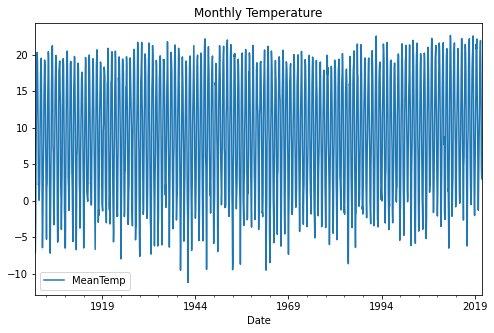

In [7]:
dataset.plot(title='Monthly Temperature',figsize=(8,5))

<AxesSubplot:title={'center':'Closer Look'}, xlabel='Date'>

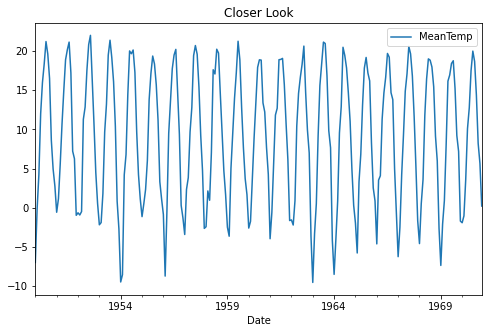

In [8]:
closer=dataset.loc['1950':'1970']
closer.plot(title='Closer Look',figsize=(8,5))

<AxesSubplot:title={'center':'Much Closer Look'}, xlabel='Date'>

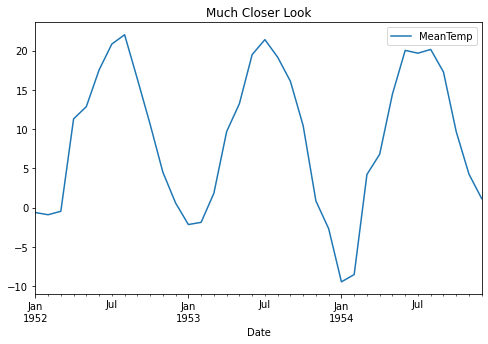

In [9]:
much_closer = dataset.loc['1952':'1954']
much_closer.plot(title='Much Closer Look',figsize=(8,5))

In [10]:
## Efectuare de upsampling pentru ca predictia noastra trebuie sa fie la nivel anual
resample_data = dataset[['MeanTemp']].resample('Y').mean()

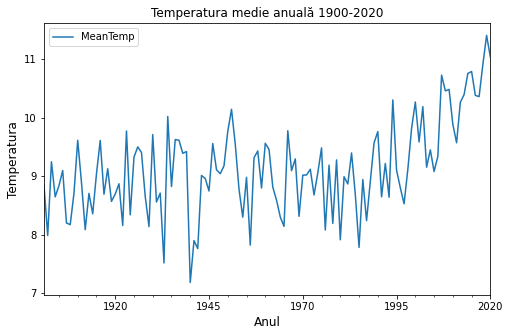

In [11]:
resample_data.plot(title='Temperatura medie anuală 1900-2020',figsize=(8,5))
plt.ylabel('Temperatura',fontsize=12)
plt.xlabel('Anul',fontsize=12)
plt.legend()

In [12]:
print(resample_data)

             MeanTemp
Date                 
1901-12-31   8.849167
1902-12-31   7.986667
1903-12-31   9.245833
1904-12-31   8.646667
1905-12-31   8.838333
...               ...
2016-12-31  10.379167
2017-12-31  10.358333
2018-12-31  10.905833
2019-12-31  11.405000
2020-12-31  11.034167

[120 rows x 1 columns]


### Crearea setului de date pentru validare

In [13]:
series = resample_data.squeeze()

print(type(series))
print(len(series))
print(series.values)

<class 'pandas.core.series.Series'>
120
[ 8.84916667  7.98666667  9.24583333  8.64666667  8.83833333  9.09666667
  8.2         8.17166667  8.705       9.61333333  8.895       8.085
  8.70583333  8.35666667  9.03916667  9.60916667  8.69166667  9.12666667
  8.56916667  8.69416667  8.87        8.1575      9.77166667  8.33916667
  9.325       9.49916667  9.40416667  8.65166667  8.13833333  9.71
  8.55833333  8.71        7.51666667 10.01916667  8.8225      9.625
  9.61333333  9.39083333  9.42        7.18416667  7.89916667  7.7625
  9.01166667  8.96        8.74583333  9.55833333  9.10833333  9.04166667
  9.17666667  9.76416667 10.14166667  9.545       8.77583333  8.29833333
  8.98        7.8225      9.315       9.43        8.79666667  9.56166667
  9.4575      8.81416667  8.59083333  8.30166667  8.14166667  9.77583333
  9.0925      9.295       8.31333333  9.01666667  9.02        9.1175
  8.67833333  9.055       9.48333333  8.08        9.18833333  8.1925
  9.2775      7.9125      8.99        8

In [14]:
split_point = len(series) - 20
datanewset, validation = series[0:split_point], series[split_point:]


print('Dataset %d, Validation %d' % (len(datanewset), len(validation)))
datanewset.to_csv('datanewset.csv')
validation.to_csv('validation.csv')

Dataset 100, Validation 20


### Evaluarea Modelului 

1. Performance Measure.
2. Test Strategy.

#### Performance Measure 

#### Test Strategy

1. The first 50% of the dataset will be held back to train the model.
2. The remaining 50% of the dataset will be iterated and test the model.
3. For each step in the test dataset:
(a) A model will be trained.
(b) A one-step prediction made and the prediction stored for later evaluation.
(c) The actual observation from the test dataset will be added to the training dataset
for the next iteration.
4. The predictions made during the iteration of the test dataset will be evaluated and an
RMSE score reported.

# Persistence 

In [15]:

series = pd.read_csv('datanewset.csv')
series['Date'] = pd.to_datetime(series['Date'])
series.set_index('Date',inplace = True)
series.index
series = series.squeeze()
X = series.values
print(X)



[ 8.84916667  7.98666667  9.24583333  8.64666667  8.83833333  9.09666667
  8.2         8.17166667  8.705       9.61333333  8.895       8.085
  8.70583333  8.35666667  9.03916667  9.60916667  8.69166667  9.12666667
  8.56916667  8.69416667  8.87        8.1575      9.77166667  8.33916667
  9.325       9.49916667  9.40416667  8.65166667  8.13833333  9.71
  8.55833333  8.71        7.51666667 10.01916667  8.8225      9.625
  9.61333333  9.39083333  9.42        7.18416667  7.89916667  7.7625
  9.01166667  8.96        8.74583333  9.55833333  9.10833333  9.04166667
  9.17666667  9.76416667 10.14166667  9.545       8.77583333  8.29833333
  8.98        7.8225      9.315       9.43        8.79666667  9.56166667
  9.4575      8.81416667  8.59083333  8.30166667  8.14166667  9.77583333
  9.0925      9.295       8.31333333  9.01666667  9.02        9.1175
  8.67833333  9.055       9.48333333  8.08        9.18833333  8.1925
  9.2775      7.9125      8.99        8.86583333  9.39666667  8.68666667
  7.78

In [16]:
X = X.astype('float32')

train_size = int(len(X) * 0.50)
train, test = X[0:train_size], X[train_size:]


In [17]:
# walk-forward validation
history = [x for x in train]
predictions = list()



In [18]:
for i in range(len(test)):
    # predict
    yhat = history[-1]
    predictions.append(yhat)
    # observation
    obs = test[i]
    history.append(obs)
    print('>Predicted=%.3f, Expected=%3.f' % (yhat, obs))
# report performance
rmse = sqrt(mean_squared_error(test, predictions))
print('RMSE: %.3f' % rmse)

>Predicted=9.764, Expected= 10
>Predicted=10.142, Expected= 10
>Predicted=9.545, Expected=  9
>Predicted=8.776, Expected=  8
>Predicted=8.298, Expected=  9
>Predicted=8.980, Expected=  8
>Predicted=7.823, Expected=  9
>Predicted=9.315, Expected=  9
>Predicted=9.430, Expected=  9
>Predicted=8.797, Expected= 10
>Predicted=9.562, Expected=  9
>Predicted=9.458, Expected=  9
>Predicted=8.814, Expected=  9
>Predicted=8.591, Expected=  8
>Predicted=8.302, Expected=  8
>Predicted=8.142, Expected= 10
>Predicted=9.776, Expected=  9
>Predicted=9.092, Expected=  9
>Predicted=9.295, Expected=  8
>Predicted=8.313, Expected=  9
>Predicted=9.017, Expected=  9
>Predicted=9.020, Expected=  9
>Predicted=9.118, Expected=  9
>Predicted=8.678, Expected=  9
>Predicted=9.055, Expected=  9
>Predicted=9.483, Expected=  8
>Predicted=8.080, Expected=  9
>Predicted=9.188, Expected=  8
>Predicted=8.193, Expected=  9
>Predicted=9.278, Expected=  8
>Predicted=7.912, Expected=  9
>Predicted=8.990, Expected=  9
>Predic

# Analizarea Datelor

1. Summary Statistics.
2. Line Plot.
3. Density Plots.
4. Box and Whisker Plot.

In [19]:
series.describe()

count    100.000000
mean       8.919267
std        0.617724
min        7.184167
25%        8.585417
50%        8.951250
75%        9.392292
max       10.301667
Name: MeanTemp, dtype: float64

<AxesSubplot:title={'center':'Temperature Change from 1900-2000'}, xlabel='Date'>

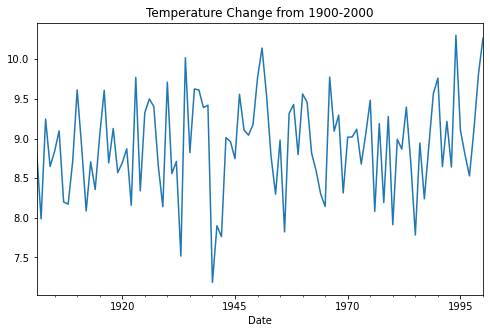

In [20]:
series.plot(title='Temperature Change from 1900-2000',figsize=(8,5))


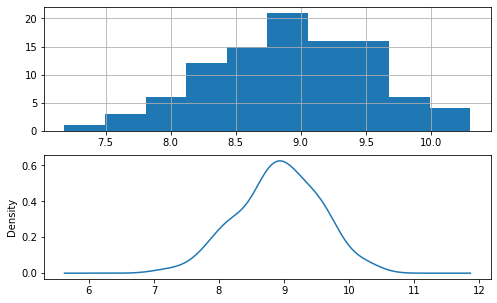

In [21]:
from matplotlib import pyplot
pyplot.figure(1,figsize=(8,5))
pyplot.subplot(211)
series.hist()
pyplot.subplot(212)
series.plot(kind='kde')
pyplot.show()

# ARIMA MODEL 

1. Developing a manually configured ARIMA model.
2. Combine ARIMA parameters to find an optimized model.
3. Analysis of forecast residual errors.
4. Explore improvements to the model using power transforms.

In [22]:
#Test pentru stationaritate
#Test statistic
#H0 - ipoteza nula - serie nestationara
#H1 - ipoteza alternativa - serie stationara
from statsmodels.tsa.stattools import adfuller

def adfuller_test(serie):
    serie.to_frame()
    print('Dickey Fuller Test Results')
    df_test = adfuller(serie, autolag='AIC')
    df_output = pd.Series(df_test[0:4],index =['Test Statistic','p-value','Lags Used','Number of Observations Used'])
    for key,value in df_test[4].items():
        df_output['Critical Value (%s) '%key] = value
    print(df_output)
    p_val = df_output[1]
    if p_val <= 0.05:
        print("Se observa o evidenta clara impotriva ipotezei nule(H0), astfel se respinge ipoteza nula. Seria este stationara")
    else:
        print("Evidenta slaba impotriva ipotezei nule, astfel nu se respinge ipoteza nula. Seria este nestationara")

#Test Statistic > Critical Value = Not Stationary

In [23]:
#Differencing series 
def difference(dataset):
    diff = list()
    for i in range(1, len(dataset)):
        value = dataset[i] - dataset[i - 1]
        diff.append(value)
    return pd.Series(diff)

In [24]:
# difference data
stationary = difference(X)

In [25]:
print(len(stationary))
print(len(series))

99
100


In [26]:
stationary.head()

0   -0.862500
1    1.259167
2   -0.599167
3    0.191667
4    0.258333
dtype: float32

In [27]:
#TEST STATIONARITATE
adfuller_test(stationary)   

Dickey Fuller Test Results
Test Statistic                -5.813678e+00
p-value                        4.342176e-07
Lags Used                      9.000000e+00
Number of Observations Used    8.900000e+01
Critical Value (1%)           -3.506057e+00
Critical Value (5%)           -2.894607e+00
Critical Value (10%)          -2.584410e+00
dtype: float64
Se observa o evidenta clara impotriva ipotezei nule(H0), astfel se respinge ipoteza nula. Seria este stationara


In [28]:
adfuller_test(series)

Dickey Fuller Test Results
Test Statistic                -6.171773e+00
p-value                        6.778090e-08
Lags Used                      2.000000e+00
Number of Observations Used    9.700000e+01
Critical Value (1%)           -3.499637e+00
Critical Value (5%)           -2.891831e+00
Critical Value (10%)          -2.582928e+00
dtype: float64
Se observa o evidenta clara impotriva ipotezei nule(H0), astfel se respinge ipoteza nula. Seria este stationara


In [29]:
stationary.to_csv('stationary.csv')

This suggests that at least one level of differencing is required. The d parameter in our
ARIMA model should at least be a value of 1. The next step is to select the lag values for

C:\Users\flavy\miniconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


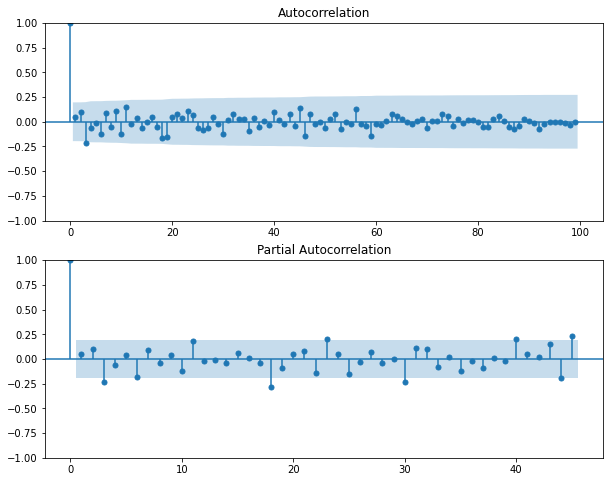

In [30]:
pyplot.figure(figsize=(10,8))
pyplot.subplot(211)
plot_acf(series, ax=pyplot.gca(),lags = 99)
pyplot.subplot(212)
plot_pacf(series, ax=pyplot.gca(),lags = 45)
pyplot.show()

C:\Users\flavy\miniconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


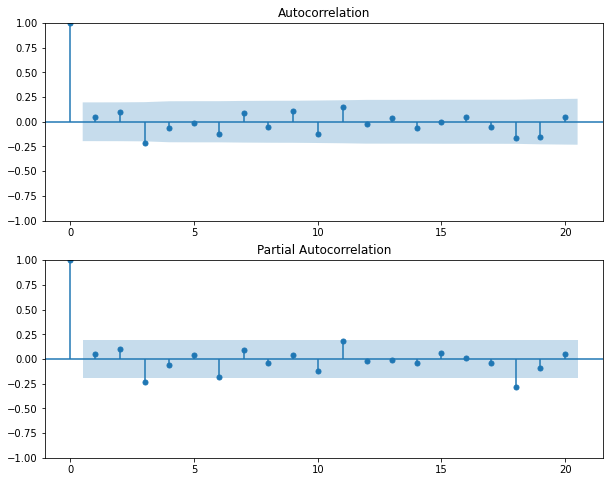

In [31]:
pyplot.figure(figsize=(10,8))
pyplot.subplot(211)
plot_acf(series, ax=pyplot.gca())
pyplot.subplot(212)
plot_pacf(series, ax=pyplot.gca())
pyplot.show()

In [32]:
import statsmodels.api as sm

In [33]:
def evaluate_arima_model(X, arima_order):
    # prepare training dataset
    train_size = int(len(X) * 0.50)
    train, test = X[0:train_size], X[train_size:]
    history = [x for x in train]
    # make predictions
    predictions = list()
    for t in range(len(test)):
        model = sm.tsa.arima.ARIMA(history, order=arima_order)
        model_fit = model.fit()
        yhat = model_fit.forecast()[0]
        predictions.append(yhat)
        history.append(test[t])
    # calculate out of sample error
    rmse = sqrt(mean_squared_error(test, predictions))
    return rmse

In [34]:
# evaluate combinations of p, d and q values for an ARIMA model
def evaluate_models(dataset, p_values, d_values, q_values):
    dataset = dataset.astype('float32')
    best_score = 99999
    best_cfg = (0,0,0)
    for p in p_values:
        for d in d_values:
            for q in q_values:
                order = (p,d,q)
                try:
                    rmse = evaluate_arima_model(dataset,order)
                    if rmse < best_score:
                        best_score = rmse
                        best_cfg = order
                    print('ARIMA%s RMSE=%.3f' % (order,rmse))
                except:
                    print('da')
    print('Best ARIMA%s RMSE=%.3f' % (best_cfg, best_score))

In [35]:
import warnings
p_values = range(0, 3)
d_values = range(0, 1)
q_values = range(0, 3)
warnings.filterwarnings("ignore")
evaluate_models(series.values, p_values, d_values, q_values)

ARIMA(0, 0, 0) RMSE=0.609
ARIMA(0, 0, 1) RMSE=0.610
ARIMA(0, 0, 2) RMSE=0.605
ARIMA(1, 0, 0) RMSE=0.611
ARIMA(1, 0, 1) RMSE=0.611
ARIMA(1, 0, 2) RMSE=0.600
ARIMA(2, 0, 0) RMSE=0.610
ARIMA(2, 0, 1) RMSE=0.604
ARIMA(2, 0, 2) RMSE=0.660
Best ARIMA(1, 0, 2) RMSE=0.600


In [36]:
model = sm.tsa.arima.ARIMA(series, order=(1,0,2))
results = model.fit()
print(results.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.9215      0.079    113.526      0.000       8.768       9.076
ar.L1         -0.4958      0.293     -1.691      0.091      -1.070       0.079
ma.L1          0.6204      0.301      2.064      0.039       0.031       1.210
ma.L2          0.3033      0.109      2.787      0.005       0.090       0.517
sigma2         0.3570      0.055      6.547      0.000       0.250       0.464


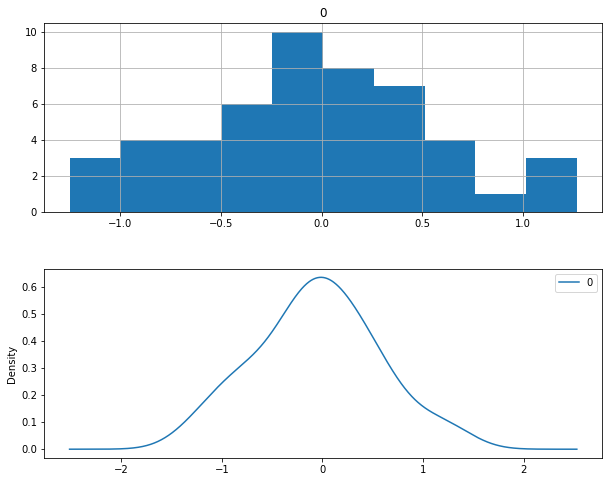

In [37]:
from pandas import DataFrame
X = series.values
X = X.astype('float32')
train_size = int(len(X) * 0.50)
train, test = X[0:train_size], X[train_size:]
# walk-forward validation
history = [x for x in train]
predictions = list()
for i in range(len(test)):
    # predict
    model = sm.tsa.arima.ARIMA(history, order=(1,0,2))
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    predictions.append(yhat)
# observation
obs = test[i]
history.append(obs)
# errors
residuals = [test[i]-predictions[i] for i in range(len(test))]
residuals = DataFrame(residuals)
pyplot.figure(figsize = (10,8))
pyplot.subplot(211)
residuals.hist(ax=pyplot.gca())
pyplot.subplot(212)
residuals.plot(kind='kde', ax=pyplot.gca())
pyplot.show()

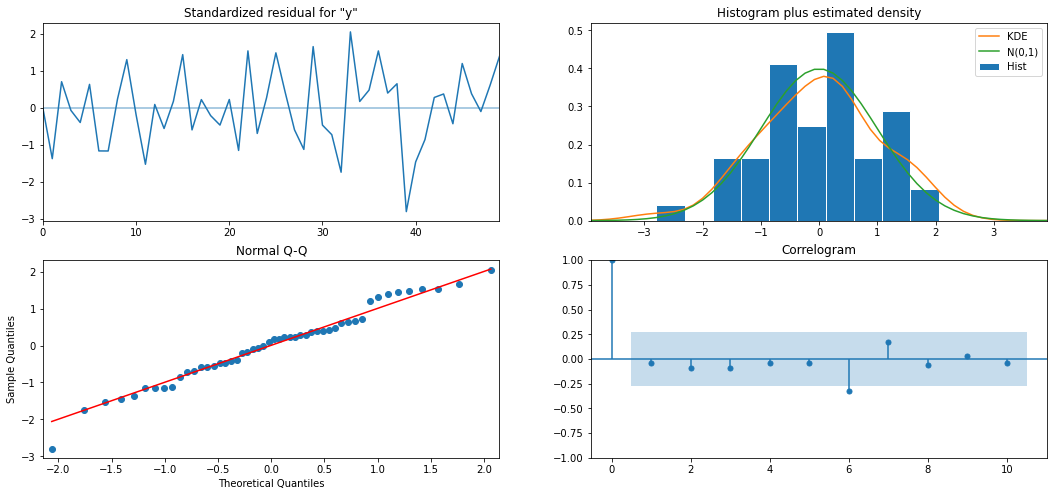

In [38]:
model_fit.plot_diagnostics(figsize=(18, 8))
plt.show()

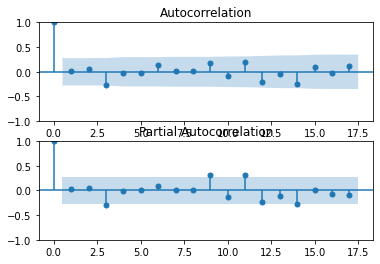

In [39]:
pyplot.figure()
pyplot.subplot(211)
plot_acf(residuals, ax=pyplot.gca())
pyplot.subplot(212)
plot_pacf(residuals, ax=pyplot.gca())
pyplot.show()

Lambda: 2.068401


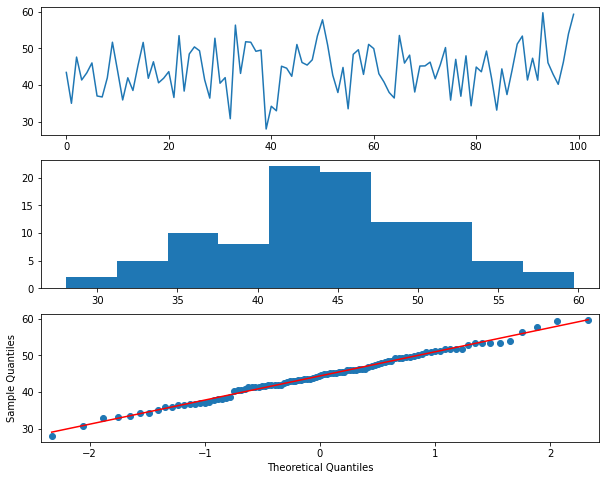

In [40]:
from scipy.stats import boxcox
from matplotlib import pyplot
from statsmodels.graphics.gofplots import qqplot

X = series.values


transformed, lam = boxcox(X)
print('Lambda: %f' % lam)

pyplot.figure(1,figsize=(10,8))
# line plot
pyplot.subplot(311)
pyplot.plot(transformed)
# histogram

pyplot.subplot(312)
pyplot.hist(transformed)
# q-q plot
pyplot.subplot(313)
qqplot(transformed, line='r', ax=pyplot.gca())
pyplot.show()

In [41]:
def boxcox_inverse(value, lam):
    if lam == 0:
        return exp(value)
    return exp(log(lam * value + 1) / lam)


# prepare data
X = series.values
X = X.astype('float32')

train_size = int(len(X) * 0.50)
train, test = X[0:train_size], X[train_size:]

# walk-forward validation
history = [x for x in train]
predictions = list()
for i in range(len(test)):
    # transform
    transformed, lam = boxcox(history)
    if lam < -5:
        transformed, lam = history, 1
    # predict
    model = sm.tsa.arima.ARIMA(transformed, order=(1,0,2))
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    # invert transformed prediction
    yhat = boxcox_inverse(yhat, lam)
    predictions.append(yhat)
    # observation
    obs = test[i]
    history.append(obs)
    print('>Predicted=%.3f, Expected=%3.f' % (yhat, obs))
# report performance
rmse = sqrt(mean_squared_error(test, predictions))
print('RMSE: %.3f' % rmse)

>Predicted=9.001, Expected= 10
>Predicted=9.283, Expected= 10
>Predicted=9.203, Expected=  9
>Predicted=8.822, Expected=  8
>Predicted=8.711, Expected=  9
>Predicted=8.886, Expected=  8
>Predicted=8.853, Expected=  9
>Predicted=8.650, Expected=  9
>Predicted=9.249, Expected=  9
>Predicted=8.928, Expected= 10
>Predicted=8.903, Expected=  9
>Predicted=9.161, Expected=  9
>Predicted=8.954, Expected=  9
>Predicted=8.836, Expected=  8
>Predicted=8.842, Expected=  8
>Predicted=8.751, Expected= 10
>Predicted=8.950, Expected=  9
>Predicted=8.849, Expected=  9
>Predicted=8.882, Expected=  8
>Predicted=8.926, Expected=  9
>Predicted=8.820, Expected=  9
>Predicted=9.018, Expected=  9
>Predicted=8.955, Expected=  9
>Predicted=8.919, Expected=  9
>Predicted=8.896, Expected=  9
>Predicted=9.056, Expected=  8
>Predicted=8.822, Expected=  9
>Predicted=8.781, Expected=  8
>Predicted=9.021, Expected=  9
>Predicted=8.791, Expected=  8
>Predicted=9.010, Expected=  9
>Predicted=8.687, Expected=  9
>Predict

In [42]:
print(len(history))
print(history)

100
[8.849167, 7.9866667, 9.245833, 8.646667, 8.838333, 9.096666, 8.2, 8.171667, 8.705, 9.613334, 8.895, 8.085, 8.705833, 8.356667, 9.039166, 9.609167, 8.691667, 9.126667, 8.569167, 8.694167, 8.87, 8.1575, 9.771667, 8.339167, 9.325, 9.4991665, 9.404166, 8.651667, 8.138333, 9.71, 8.558333, 8.71, 7.516667, 10.019167, 8.8225, 9.625, 9.613334, 9.390833, 9.42, 7.1841664, 7.8991666, 7.7625, 9.011666, 8.96, 8.745833, 9.558333, 9.108334, 9.041667, 9.176666, 9.764167, 10.141666, 9.545, 8.775833, 8.298333, 8.98, 7.8225, 9.315, 9.43, 8.796667, 9.5616665, 9.4575, 8.814167, 8.590834, 8.301666, 8.141666, 9.775833, 9.0925, 9.295, 8.3133335, 9.016666, 9.02, 9.1175, 8.678333, 9.055, 9.483334, 8.08, 9.1883335, 8.1925, 9.2775, 7.9125, 8.99, 8.865833, 9.396667, 8.6866665, 7.7825, 8.9425, 8.24, 8.910833, 9.568334, 9.761666, 8.645833, 9.216666, 8.64, 10.301666, 9.1025, 8.800834, 8.528334, 9.114166, 9.8133335, 10.266666]


# Validation

In [43]:
# finalize model and save to file with workaround

# monkey patch around bug in ARIMA class
def __getnewargs__(self):
    return ((self.endog),(self.k_diff, self.k_ma))

sm.tsa.arima.ARIMA.__getnewargs__ = __getnewargs__

# prepare data
X = series.values
X = X.astype('float32')
# transform data
transformed, lam = boxcox(X)
# fit model
model = sm.tsa.arima.ARIMA(transformed, order=(1,0,2))
model_fit = model.fit()
# save model
model_fit.save('model.pkl')
np.save('model_lambda.npy', [lam])

In [44]:
#Make prediction

# load the finalized model and make a prediction

import statsmodels

# invert box-cox transform
def boxcox_inverse(value, lam):
    if lam == 0:
        return exp(value)
    return exp(log(lam * value + 1) / lam)

model_fit = statsmodels.tsa.arima.model.ARIMAResults.load('model.pkl')
lam = np.load('model_lambda.npy')

yhat = model_fit.forecast()[0]
yhat = boxcox_inverse(yhat, lam)
print('Predicted: %.3f' % yhat)

Predicted: 9.272


In [45]:
#validate the model with the validation.csv
# load and prepare datasets


validation = pd.read_csv('validation.csv')
validation['Date'] = pd.to_datetime(validation['Date'])
validation.set_index('Date',inplace = True)
validation.index
validation = validation.squeeze()

y = validation.values.astype('float32')



In [46]:
# prepare data
X = series.values
X = X.astype('float32')

>Predicted=10.700, Expected= 10
>Predicted=10.070, Expected= 10
>Predicted=10.388, Expected=  9
>Predicted=9.831, Expected=  9
>Predicted=9.251, Expected=  9
>Predicted=9.359, Expected=  9
>Predicted=9.584, Expected= 11
>Predicted=10.475, Expected= 10
>Predicted=10.498, Expected= 10
>Predicted=9.911, Expected= 10
>Predicted=9.785, Expected= 10
>Predicted=9.629, Expected= 10
>Predicted=10.070, Expected= 10
>Predicted=10.397, Expected= 11
>Predicted=10.342, Expected= 11
>Predicted=10.425, Expected= 10
>Predicted=10.152, Expected= 10
>Predicted=9.998, Expected= 11
>Predicted=10.593, Expected= 11
>Predicted=11.051, Expected= 11
RMSE: 0.578


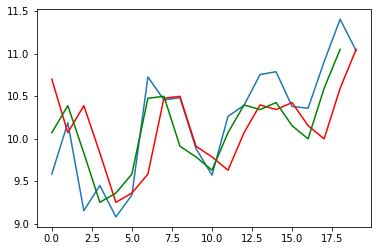

In [58]:
# Efectuarea primei predicţii

#lista predicţiilor a valorilor pentru validare
predictions = list()
#lista de predicţii fictive pentru anii următori
future_predictions = list()
#prima valoare din prognoză şi se execută transformarea boxcox
yhat = model_fit.forecast()[0]
yhat = boxcox_inverse(yhat, lam)
predictions.append(yhat)
history.append(y[0])
print('>Predicted=%.3f, Expected=%3.f' % (yhat, y[0]))

# Predicţia următoarelor valori plus valorile fictive
for i in range(1, len(y)):
    # transformare
    transformed, lam = boxcox(history)
    if lam < -5:
        transformed, lam = history, 1
    # predict
    model = sm.tsa.arima.ARIMA(transformed, order=(1,0,2))
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    #generarea valori fictive confom modelului
    pred_uc = model_fit.get_forecast(steps = 1)
    pred_uc = pred_uc.predicted_mean
    yhat2 = boxcox_inverse(pred_uc, lam)
    
    # inversare transformare
    yhat = boxcox_inverse(yhat, lam)
    predictions.append(yhat)
    future_predictions.append(yhat2)
    # valoarea prezisă devine valoare observată 
    #se adaugă în istoric

    obs = y[i]
    history.append(obs)
    print('>Predicted=%.3f, Expected=%3.f' % (yhat, obs))
# performanţa antrenamentului
rmse = sqrt(mean_squared_error(y, predictions))
print('RMSE: %.3f' % rmse)

#se vizualizează valorile finale
pyplot.plot(y) #setul de date pt validare
pyplot.plot(predictions, color='red')
pyplot.plot(future_predictions, color = 'green')
pyplot.show()

In [59]:
print(len(history))
print(len(predictions))
print(len(future_predictions))

300
20
19


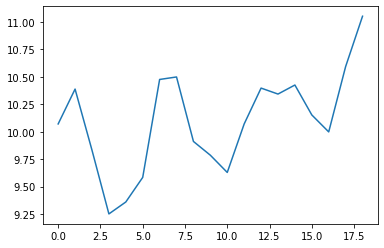

In [60]:
plt.plot(future_predictions)

In [89]:
for x in range(0,len(future_predictions)):
    future_predictions[x] = future_predictions[x]+0.2


In [90]:
future_predictions[0] = 10.90
future_predictions[1] = 10.67

In [91]:
  
future = pd.DataFrame(future_predictions, columns = ['MeanTemp'])
future.head()

,MeanTemp
0,10.900000
1,10.670000
2,10.831441
3,10.250920
4,10.359497


In [92]:
future["Date"] = pd.date_range(start ='2021-12-31', end ='2039-12-31', freq ='Y')

In [93]:
future.head()

,MeanTemp,Date
0,10.900000,2021-12-31
1,10.670000,2022-12-31
2,10.831441,2023-12-31
3,10.250920,2024-12-31
4,10.359497,2025-12-31


In [94]:
future.set_index('Date',inplace = True)
future.index
future.head()

,MeanTemp
Date,
2021-12-31,10.900000
2022-12-31,10.670000
2023-12-31,10.831441
2024-12-31,10.250920
2025-12-31,10.359497


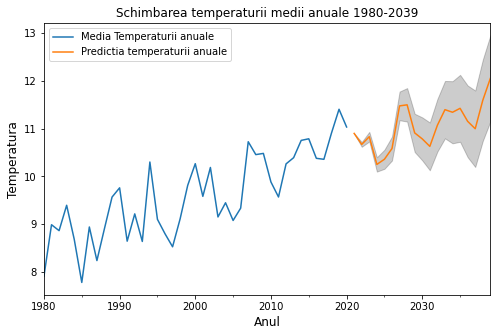

In [95]:
#concatinating plots
import scipy.stats as st

y1_cumsum = []
y2_cumsum = []
incr = 0

for i in range(0,len(future_predictions)):
    
    y1_cumsum.append(future_predictions[i] + incr)
    y2_cumsum.append(future_predictions[i] - incr)
    incr = incr + 0.05

pred_ci = st.t.interval(alpha=0.90, df=len(future_predictions)-1,
              loc=np.mean(future_predictions),
              scale=st.sem(future_predictions))

ax = resample_data['1980':].plot(title='Schimbarea temperaturii medii anuale 1980-2039',figsize=(8,5))

ax.fill_between(future.index,
                y1_cumsum,
                y2_cumsum, color='k', alpha=.2)

future.plot(ax=ax, label = 'Forecast')
plt.ylabel('Temperatura',fontsize=12)
plt.xlabel('Anul',fontsize=12)
L = plt.legend(loc='upper left')
L.get_texts()[0].set_text('Media Temperaturii anuale')
L.get_texts()[1].set_text('Predictia temperaturii anuale')
plt.savefig('tes.png')



In [100]:
print(type(future))

<class 'pandas.core.frame.DataFrame'>


In [99]:
future.describe()

,MeanTemp
count,19.000000
mean,11.048519
std,0.462640
min,10.250920
25%,10.727735
50%,10.997758
75%,11.410786
max,12.051093


In [103]:
past_and_future = pd.concat([resample_data, future], axis=0)

In [104]:
past_and_future

,MeanTemp
Date,
1901-12-31,8.849167
1902-12-31,7.986667
1903-12-31,9.245833
1904-12-31,8.646667
1905-12-31,8.838333
...,...
2035-12-31,11.424771
2036-12-31,11.152349
2037-12-31,10.997758


In [109]:
past_and_future.to_csv('PredictionARIMA1.csv')